<a href="https://colab.research.google.com/github/2244vani/AI-Resume-Screening-Recruitment-System/blob/main/Copy_of_oose_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls

drive  sample_data


In [ ]:
%cd drive/MyDrive/facial_expreession/

/content/drive/MyDrive/facial_expreession


In [ ]:
!ls

 checkpoint   fer2013  'fer2013 (1).tar.gz'


In [ ]:
import tarfile


fname = 'fer2013 (1).tar.gz'
if fname.endswith("tar.gz"):
    tar = tarfile.open(fname, "r:gz")
    tar.extractall()
    tar.close()
elif fname.endswith("tar"):
    tar = tarfile.open(fname, "r:")
    tar.extractall()
    tar.close()

In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as pyplot
# Corrected the import statement to use 'train_test_split'
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv('fer2013/fer2013.csv')
df.head()

,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


In [ ]:
df.emotion.unique()

array([0, 2, 4, 6, 3, 5, 1])

In [ ]:
label_to_text = {0:'anger', 1:'disgust', 2:'fear', 3:'happiness', 4: 'sadness', 5: 'surprise', 6: 'neutral'}

In [ ]:
np.array(df.pixels.loc[0].split(' ')).reshape(48,48)
# Split by space (' ') which is the default delimiter when split() is called without arguments

array([['70', '80', '82', ..., '52', '43', '41'],
       ['65', '61', '58', ..., '56', '52', '44'],
       ['50', '43', '54', ..., '49', '56', '47'],
       ...,
       ['91', '65', '42', ..., '72', '56', '43'],
       ['77', '82', '79', ..., '105', '70', '46'],
       ['77', '72', '84', ..., '106', '109', '82']], dtype='<U3')

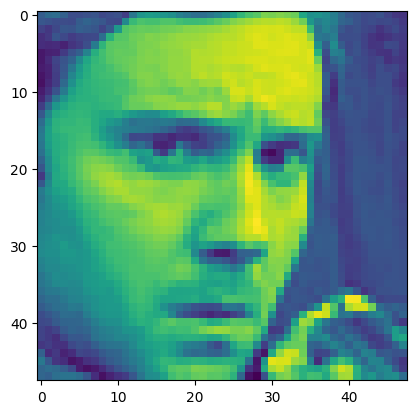

In [ ]:
pyplot.imshow(np.array(df.pixels.loc[0].split(' ')).reshape(48,48) .astype('float'))

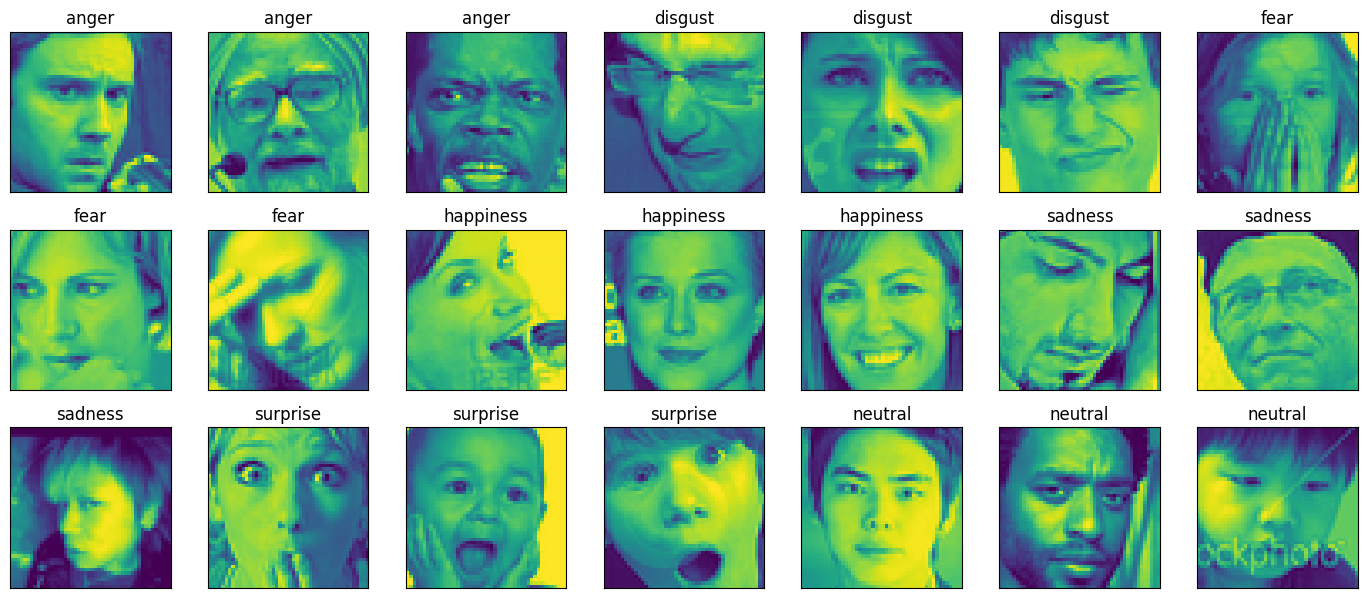

In [ ]:
fig = pyplot.figure(1, (14, 14))
k = 0
for label in sorted(df.emotion.unique()):
    for j in range(3):
        px = df[df.emotion==label].pixels.iloc[k]
        px = np.array(px.split(' ')).reshape(48, 48).astype('float32')
        k += 1
        ax = pyplot.subplot(7, 7, k)
        ax.imshow(px)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(label_to_text[label])
        pyplot.tight_layout()

In [ ]:
img_array=df.pixels.apply(lambda x : np.array(x.split(' ')).reshape(48, 48,1).astype('float32'))

In [ ]:
img_array = np.stack(img_array,axis=0)

In [ ]:
img_array.shape

(35887, 48, 48, 1)

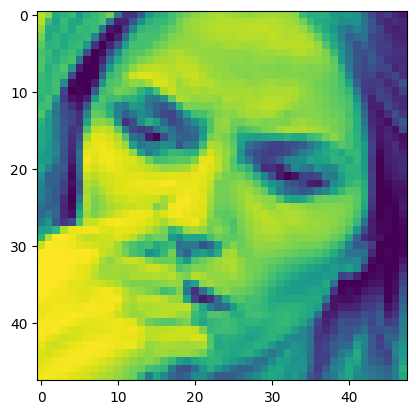

In [ ]:
pyplot.imshow(img_array[2])

In [ ]:
labels=df.emotion.values

split the dataset into training and testing

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(img_array, labels, test_size=.1) # Corrected the variable assignment to include y_train

In [ ]:
x_train.shape,y_train.shape,x_test.shape,y_test.shape

((32298, 48, 48, 1), (32298,), (3589, 48, 48, 1), (3589,))

In [ ]:
x_train = x_train/255
x_test = x_test/255

In [ ]:
basemodel = tf.keras.models.Sequential([tf.keras.layers.Conv2D(32,(3,3),activation='relu',input_shape = (48,48,1)),
                                        tf.keras.layers.MaxPool2D(2,2),
                                        tf.keras.layers.BatchNormalization(),
                                        #
                                        tf.keras.layers.Conv2D(64,(3,3),activation='relu',input_shape = (48,48,1)),
                                        tf.keras.layers.MaxPool2D(2,2),
                                        tf.keras.layers.BatchNormalization(),
                                        #
                                        tf.keras.layers.Conv2D(128,(3,3),activation='relu',input_shape = (48,48,1)),
                                        tf.keras.layers.MaxPool2D(2,2),
                                        tf.keras.layers.BatchNormalization(),
                                        #
                                        tf.keras.layers.Flatten(),
                                        tf.keras.layers.Dense(128,activation='relu'),
                                        tf.keras.layers.Dense(7,activation = 'softmax')





                                        ])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
basemodel.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)                   │ (None, 46, 46, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_28 (MaxPooling2D)      │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_28               │ (None, 23, 23, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_29 (Conv2D)                   │ (None, 21, 21, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_29 (MaxPooling2D)      │ (None, 10, 10, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_29               │ (None, 10, 10, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_30 (Conv2D)                   │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_30 (MaxPooling2D)      │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_30               │ (None, 4, 4, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 356,743 (1.36 MB)

 Trainable params: 356,295 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
basemodel.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=.0001),
                  loss ='sparse_caterogical_crossentropy',
                  metrics=['accuracy'])

In [ ]:
import os
try:
  os.mkdir('checkpoint')
except:
  pass

In [ ]:
import tensorflow as tf # Import tensorflow

file_name ='best_model.h5'
checkpoint_path=os.path.join('checkpoint',file_name)

call_back = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                               monitor='val_accuracy',
                                               verbose=1,
                                               save_freq='epoch',
                                               save_best_only=True,
                                               save_weights_only=False, # Changed 'false' to 'False'
                                               mode='max')

In [ ]:
basemodel.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=.0001),
                  loss ='sparse_categorical_crossentropy', # Corrected the typo in the loss function name
                  metrics=['accuracy'])

In [ ]:
basemodel.fit(x_train,y_train,epochs=20,validation_split=.1,callbacks=call_back)

Epoch 1/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.3321 - loss: 1.7621
Epoch 1: val_accuracy improved from -inf to 0.43839, saving model to checkpoint/best_model.h5


909/909 ━━━━━━━━━━━━━━━━━━━━ 120s 129ms/step - accuracy: 0.3322 - loss: 1.7618 - val_accuracy: 0.4384 - val_loss: 1.5033
Epoch 2/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.4894 - loss: 1.3523
Epoch 2: val_accuracy improved from 0.43839 to 0.46749, saving model to checkpoint/best_model.h5


909/909 ━━━━━━━━━━━━━━━━━━━━ 143s 131ms/step - accuracy: 0.4894 - loss: 1.3523 - val_accuracy: 0.4675 - val_loss: 1.4356
Epoch 3/20
909/909 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.5664 - loss: 1.1764
Epoch 3: val_accuracy improved from 0.46749 to 0.48638, saving model to checkpoint/best_model.h5


909/909 ━━━━━━━━━━━━━━━━━━━━ 139s 127ms/step - accuracy: 0.5664 - loss: 1.1764 - val_accuracy: 0.4864 - val_loss: 1.3704
Epoch 4/20
909/909 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.6098 - loss: 1.0593
Epoch 4: val_accuracy did not improve from 0.48638
909/909 ━━━━━━━━━━━━━━━━━━━━ 141s 127ms/step - accuracy: 0.6098 - loss: 1.0593 - val_accuracy: 0.4824 - val_loss: 1.4093
Epoch 5/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.6700 - loss: 0.9220
Epoch 5: val_accuracy improved from 0.48638 to 0.51672, saving model to checkpoint/best_model.h5


909/909 ━━━━━━━━━━━━━━━━━━━━ 143s 128ms/step - accuracy: 0.6699 - loss: 0.9220 - val_accuracy: 0.5167 - val_loss: 1.3501
Epoch 6/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.7154 - loss: 0.8246
Epoch 6: val_accuracy did not improve from 0.51672
909/909 ━━━━━━━━━━━━━━━━━━━━ 139s 124ms/step - accuracy: 0.7154 - loss: 0.8246 - val_accuracy: 0.5146 - val_loss: 1.3526
Epoch 7/20
909/909 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.7537 - loss: 0.7277
Epoch 7: val_accuracy improved from 0.51672 to 0.53282, saving model to checkpoint/best_model.h5


909/909 ━━━━━━━━━━━━━━━━━━━━ 147s 131ms/step - accuracy: 0.7537 - loss: 0.7277 - val_accuracy: 0.5328 - val_loss: 1.3803
Epoch 8/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.7903 - loss: 0.6422
Epoch 8: val_accuracy did not improve from 0.53282
909/909 ━━━━━━━━━━━━━━━━━━━━ 113s 124ms/step - accuracy: 0.7903 - loss: 0.6422 - val_accuracy: 0.5164 - val_loss: 1.4290
Epoch 9/20
909/909 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.8269 - loss: 0.5540
Epoch 9: val_accuracy did not improve from 0.53282
909/909 ━━━━━━━━━━━━━━━━━━━━ 145s 128ms/step - accuracy: 0.8269 - loss: 0.5540 - val_accuracy: 0.5276 - val_loss: 1.4360
Epoch 10/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.8580 - loss: 0.4783
Epoch 10: val_accuracy did not improve from 0.53282
909/909 ━━━━━━━━━━━━━━━━━━━━ 140s 126ms/step - accuracy: 0.8580 - loss: 0.4783 - val_accuracy: 0.5170 - val_loss: 1.5252
Epoch 11/20
908/909 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.8852 - loss: 0.4094
Epoch 11

KeyboardInterrupt: 

In [ ]:
basemodel.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=.0001),
                  loss ='sparse_categorical_crossentropy', # Corrected the typo in the loss function name
                  metrics=['accuracy'])

actual label is surprise
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
predicted label is surprise


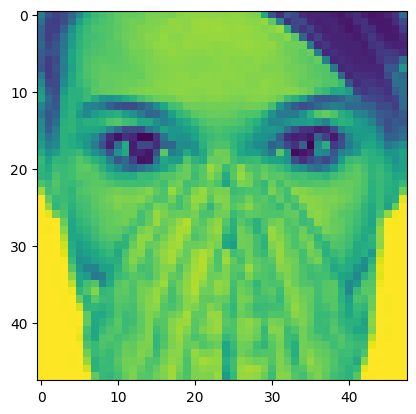

In [ ]:


from IPython.display import clear_output # Corrected the import statement to use 'IPython'
import time
for k in range(40): # Corrected the typo in the loop variable name from 'rane' to 'range'
  print(f'actual label is {label_to_text[y_test[k]]}')
  predicted_class = basemodel.predict(tf.expand_dims(x_test[k],0)).argmax() # Assuming 'final_model' should be 'basemodel' as it was trained earlier
  print(f'predicted label is {label_to_text[predicted_class]}')
  pyplot.imshow(x_test[k].reshape((48,48)))
  pyplot.show()
  time.sleep(5)
  clear_output(wait=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!find /content/drive/MyDrive -name "*.h5"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/facial_expreession/checkpoint/best_model.h5
/content/drive/MyDrive/facial_expreession/model.weights.h5


In [ ]:
!pip install opencv-python numpy tensorflow keras


In [ ]:
from google.colab import output
import cv2
import numpy as np
import PIL
import io
import IPython.display
from base64 import b64decode

def take_photo():
    js = """
    async function takePhoto() {
        // **Request user permission**
        try {
            await navigator.mediaDevices.getUserMedia({ video: true });
        } catch (err) {
            alert('Permission denied or camera not available.');
            throw err; // Re-throw the error to stop execution
        }

        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture';
        div.appendChild(capture);
        document.body.appendChild(div);

        const video = document.createElement('video');
        div.appendChild(video);
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        video.srcObject = stream;
        await new Promise((resolve) => video.onloadedmetadata = resolve);
        video.play();

        await new Promise((resolve) => capture.onclick = resolve);
        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/png');
    }
    """
    display(IPython.display.Javascript(js))
    data = output.eval_js('takePhoto()')
    binary = b64decode(data.split(',')[1])
    image = PIL.Image.open(io.BytesIO(binary))
    return image

# Capture image
image = take_photo()
image.save('captured_image.png')
image.show()

<IPython.core.display.Javascript object>

In [ ]:
# Load your trained model
import tensorflow as tf

model = tf.keras.models.load_model("/content/drive/MyDrive/facial_expreession/checkpoint/best_model.h5")

# Load and preprocess image
def preprocess_image(image_path):
    img = PIL.Image.open(image_path).convert('L')  # Convert to grayscale
    img = img.resize((48, 48))  # Resize to FER2013 format
    img_array = np.array(img) / 255.0  # Normalize
    img_array = img_array.reshape(1, 48, 48, 1)  # Reshape for model
    return img_array

# Run emotion prediction
emotion_classes = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
img_array = preprocess_image('captured_image.png')
prediction = model.predict(img_array)
emotion = emotion_classes[np.argmax(prediction)]

print(f"Detected Emotion: {emotion}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step
Detected Emotion: Surprise


In [ ]:
!find /content/drive/MyDrive/ -name "fer2013.csv"


find: ‘/content/drive/MyDrive/’: No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls

 checkpoint   fer2013  'fer2013 (1).tar.gz'   model.json   model.weights.h5


In [ ]:
!ls

 checkpoint   fer2013  'fer2013 (1).tar.gz'   model.json   model.weights.h5


In [ ]:
import pandas as pd
import tarfile

# Open the tar archive
tar = tarfile.open('fer2013 (1).tar.gz', "r:gz")

# Extract the desired CSV file
# Assuming the CSV file is named 'fer2013.csv' and is in a folder named 'fer2013'
csv_member = tar.getmember('fer2013/fer2013.csv')
csv_file = tar.extractfile(csv_member)

# Read the CSV file into a pandas DataFrame
df = pd.read_csv(csv_file)

# Close the tar archive
tar.close()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully!
Test data loaded successfully!
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step


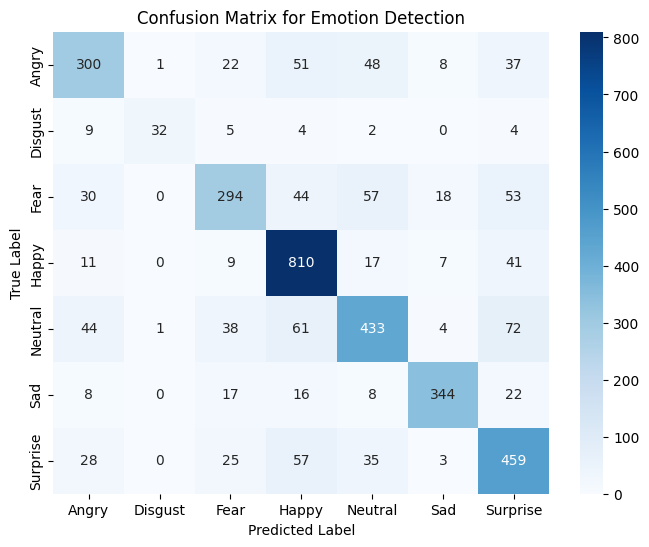


Classification Report:
               precision    recall  f1-score   support

       Angry       0.70      0.64      0.67       467
     Disgust       0.94      0.57      0.71        56
        Fear       0.72      0.59      0.65       496
       Happy       0.78      0.91      0.84       895
     Neutral       0.72      0.66      0.69       653
         Sad       0.90      0.83      0.86       415
    Surprise       0.67      0.76      0.71       607

    accuracy                           0.74      3589
   macro avg       0.77      0.71      0.73      3589
weighted avg       0.75      0.74      0.74      3589



In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# **Define Paths**
model_path = "/content/drive/MyDrive/facial_expreession/checkpoint/best_model.h5"
test_data_path = "/content/drive/MyDrive/facial_expreession/fer2013/fer2013.csv"

# **Load Model**
if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path)
    print("Model loaded successfully!")
else:
    raise FileNotFoundError(f"Model file not found at: {model_path}")

# **Load Test Data**
if os.path.exists(test_data_path):
    df = pd.read_csv(test_data_path)
    print("Test data loaded successfully!")
else:
    raise FileNotFoundError(f"Test dataset not found at: {test_data_path}")

# **Extract Test Data**
# FER2013 contains pixel values as a string, we need to process them
df_test = df[df['Usage'] == 'PublicTest']  # Adjust 'PublicTest' if needed

X_test = np.array([np.fromstring(x, dtype=int, sep=' ') for x in df_test['pixels']])
X_test = X_test.reshape(-1, 48, 48, 1) / 255.0  # Reshape and normalize

y_test = df_test['emotion'].values  # Labels

# **Make Predictions**
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# **Generate Confusion Matrix**
cm = confusion_matrix(y_test, y_pred)
class_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Emotion Detection')
plt.show()

# **Print Classification Report**
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=class_labels))


1122/1122 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step


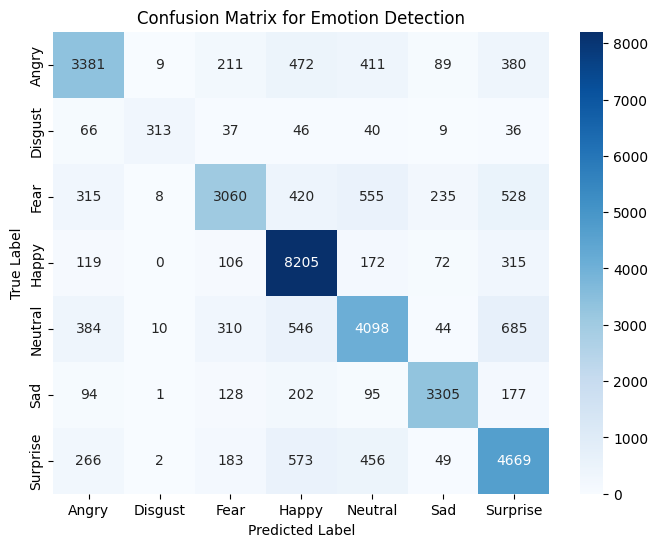


Classification Report:
Angry: Precision=0.73, Recall(Sensitivity)=0.68, F1-Score=0.71, Specificity=0.96, Support=4953.0
Disgust: Precision=0.91, Recall(Sensitivity)=0.57, F1-Score=0.70, Specificity=1.00, Support=547.0
Fear: Precision=0.76, Recall(Sensitivity)=0.60, F1-Score=0.67, Specificity=0.97, Support=5121.0
Happy: Precision=0.78, Recall(Sensitivity)=0.91, F1-Score=0.84, Specificity=0.92, Support=8989.0
Neutral: Precision=0.70, Recall(Sensitivity)=0.67, F1-Score=0.69, Specificity=0.94, Support=6077.0
Sad: Precision=0.87, Recall(Sensitivity)=0.83, F1-Score=0.85, Specificity=0.98, Support=4002.0
Surprise: Precision=0.69, Recall(Sensitivity)=0.75, F1-Score=0.72, Specificity=0.93, Support=6198.0

Overall Accuracy: 0.75


In [ ]:
import numpy as np
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Load your trained model
model_path = "/content/drive/MyDrive/facial_expreession/checkpoint/best_model.h5"
model = tf.keras.models.load_model(model_path)

# Load your test dataset
test_data_path = "/content/drive/MyDrive/facial_expreession/fer2013/fer2013.csv"

import pandas as pd
df = pd.read_csv(test_data_path)

# Extracting test images and labels
# Assuming your dataset has 'pixels' column for images and 'emotion' for labels
X_test = np.array([np.fromstring(pixel_str, sep=' ') for pixel_str in df['pixels']])
X_test = X_test.reshape(-1, 48, 48, 1) / 255.0  # Normalize the pixel values
y_test = df['emotion'].values  # Labels

# Predict classes
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)  # Convert probabilities to class labels

# Define emotion labels based on FER2013 dataset
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=emotion_labels, yticklabels=emotion_labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix for Emotion Detection")
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, target_names=emotion_labels, output_dict=True)

# Calculate Specificity for each class
specificity = {}
for i, label in enumerate(emotion_labels):
    tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])  # True Negatives
    fp = np.sum(cm[:, i]) - cm[i, i]  # False Positives
    specificity[label] = tn / (tn + fp) if (tn + fp) > 0 else 0  # Avoid division by zero

# Print classification report with specificity
print("\nClassification Report:")
for label in emotion_labels:
    precision = report[label]["precision"]
    recall = report[label]["recall"]  # Sensitivity
    f1_score = report[label]["f1-score"]
    support = report[label]["support"]
    spec = specificity[label]
    print(f"{label}: Precision={precision:.2f}, Recall(Sensitivity)={recall:.2f}, F1-Score={f1_score:.2f}, Specificity={spec:.2f}, Support={support}")

# Print overall accuracy
accuracy = report["accuracy"]
print(f"\nOverall Accuracy: {accuracy:.2f}")
